In [1]:
# 📦 Imports
import pyodbc
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns


C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
# 🔗 Connexion SQL Server
conn_str = (
    "Driver={ODBC Driver 17 for SQL Server};"
    "Server=LAPTOP-GPVK1ANC;"
    "Database=DW_SupplyChain;"
    "Trusted_Connection=yes;"
)
cnxn = pyodbc.connect(conn_str)

# 📥 Extraction des données
query = """
SELECT 
    productFK,
    brandFK,
    Production_Start_Time,
    Production_End_Time,
    manufacturedate,
    expirydate,
    Dosage,
    quantityused
FROM fact_production
"""
df = pd.read_sql(query, cnxn)

# Affichage des premières lignes du dataframe pour vérifier la structure des données
df.head()


C:\Users\ayadi\AppData\Local\Temp\ipykernel_20904\2065644576.py:23: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, cnxn)


,productFK,brandFK,Production_Start_Time,Production_End_Time,manufacturedate,expirydate,Dosage,quantityused
0,2,15,2022032723,2022032800,2024082023,2025083023,9,9
1,2,15,2022040823,2022040806,2024082023,2025083023,9,9
2,2,15,2022050523,2022050517,2024082023,2025083023,9,9
3,2,15,2022052123,2022052119,2024082023,2025083023,9,9
4,2,15,2022070123,2022070113,2024082023,2025083023,9,9


In [3]:
from sklearn.preprocessing import StandardScaler, LabelEncoder

# 1. Encoder les colonnes catégorielles (productFK et brandFK)
le_product = LabelEncoder()
le_brand = LabelEncoder()

df['productFK_encoded'] = le_product.fit_transform(df['productFK'])
df['brandFK_encoded'] = le_brand.fit_transform(df['brandFK'])

# 2. Sélectionner les colonnes pertinentes pour le clustering
X = df[['productFK_encoded', 'brandFK_encoded', 'Dosage', 'quantityused']]

# 3. Normaliser les données
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Afficher les premières lignes des données prétraitées
print(X_scaled[:5])


[[-1.71018379 -0.31865615  1.23031572  1.23281343]
 [-1.71018379 -0.31865615  1.23031572  1.23281343]
 [-1.71018379 -0.31865615  1.23031572  1.23281343]
 [-1.71018379 -0.31865615  1.23031572  1.23281343]
 [-1.71018379 -0.31865615  1.23031572  1.23281343]]


In [4]:
print(df['productFK'].value_counts())
print(df['brandFK'].value_counts())


productFK
4665    50
1520    50
2590    50
2493    50
2466    50
        ..
2018     5
573      5
1225     5
3104     5
3292     5
Name: count, Length: 1201, dtype: int64
brandFK
9      3044
16     3022
13     2950
10     2881
14     2807
       ... 
198       6
36        6
178       5
78        5
152       5
Name: count, Length: 200, dtype: int64


In [5]:
!pip install --upgrade scikit-learn
!pip install --upgrade threadpoolctl


In [16]:
from sklearn.cluster import DBSCAN

# Réajustement des paramètres
dbscan = DBSCAN(eps=0.4, min_samples=4)  # Essayer une valeur plus petite pour eps et une plus grande pour min_samples
dbscan_labels = dbscan.fit_predict(X_scaled)

# Ajouter les résultats au DataFrame
df['DBSCAN_Cluster'] = dbscan_labels

# Afficher les résultats ajustés
print(df[['productFK', 'brandFK', 'Dosage', 'quantityused', 'DBSCAN_Cluster']].head(100))


    productFK  brandFK  Dosage quantityused  DBSCAN_Cluster
0           2       15       9            9               0
1           2       15       9            9               0
2           2       15       9            9               0
3           2       15       9            9               0
4           2       15       9            9               0
..        ...      ...     ...          ...             ...
95         10       10      10           10               3
96         10       10      10           10               3
97         10       10      10           10               3
98         10       10      10           10               3
99         15       14       4            4               4

[100 rows x 5 columns]


In [12]:
from sklearn.cluster import AgglomerativeClustering

# Appliquer Agglomerative Clustering
agglo = AgglomerativeClustering(n_clusters=3)
agglo_labels = agglo.fit_predict(X_scaled)

# Ajouter les labels de clusters à notre DataFrame
df['Agglomerative_Cluster'] = agglo_labels

# Afficher les résultats
print(df[['productFK', 'brandFK', 'Dosage', 'quantityused', 'Agglomerative_Cluster']].head(50))


    productFK  brandFK  Dosage quantityused  Agglomerative_Cluster
0           2       15       9            9                      0
1           2       15       9            9                      0
2           2       15       9            9                      0
3           2       15       9            9                      0
4           2       15       9            9                      0
5           2       15       9            9                      0
6           2       15       9            9                      0
7           2       15       9            9                      0
8           2       15       9            9                      0
9           2       15       9            9                      0
10          2       15       9            9                      0
11          2       15       9            9                      0
12          2       15       9            9                      0
13          2       15       9            9                   

In [13]:
from sklearn.cluster import KMeans

# 🔁 Clustering avec k=3 
k_optimal = 3
kmeans = KMeans(n_clusters=k_optimal, random_state=42)
clusters = kmeans.fit_predict(X_scaled)  # 📊 Clustering sur les données standardisées

# 🎯 Attribution des clusters au DataFrame d'origine
df['kmeans_Cluster'] = clusters

# 📋 Afficher les 50 premières lignes avec les clusters
print(df[['productFK', 'brandFK', 'Dosage', 'quantityused', 'kmeans_Cluster']].head(50))


    productFK  brandFK  Dosage quantityused  kmeans_Cluster
0           2       15       9            9               0
1           2       15       9            9               0
2           2       15       9            9               0
3           2       15       9            9               0
4           2       15       9            9               0
5           2       15       9            9               0
6           2       15       9            9               0
7           2       15       9            9               0
8           2       15       9            9               0
9           2       15       9            9               0
10          2       15       9            9               0
11          2       15       9            9               0
12          2       15       9            9               0
13          2       15       9            9               0
14          2       15       9            9               0
15          2       15       9          

In [17]:
from sklearn.metrics import silhouette_score

# Calcul des Silhouette Scores
kmeans_score = silhouette_score(X_scaled, df['kmeans_Cluster'])
agglo_score = silhouette_score(X_scaled, df['Agglomerative_Cluster'])
dbscan_score = silhouette_score(X_scaled, df['DBSCAN_Cluster'])

# Affichage des scores
print(f"Silhouette Score KMeans: {kmeans_score:.3f}")
print(f"Silhouette Score Agglomerative Clustering: {agglo_score:.3f}")
print(f"Silhouette Score DBSCAN: {dbscan_score:.3f}")


Silhouette Score KMeans: 0.433
Silhouette Score Agglomerative Clustering: 0.422
Silhouette Score DBSCAN: -0.001


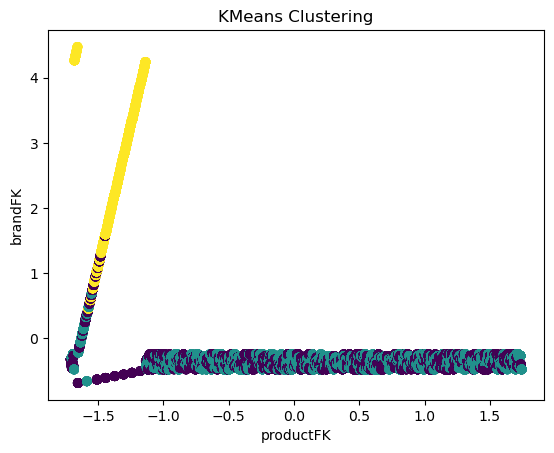

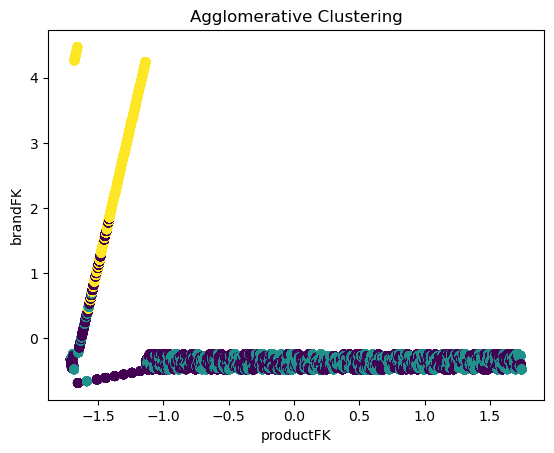

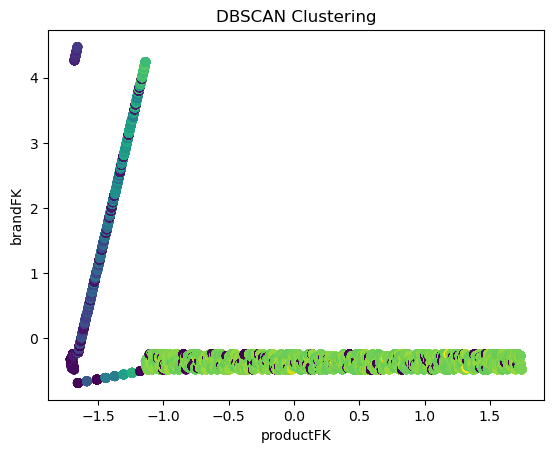

In [18]:
# Visualisation KMeans with more informative labels
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=df['kmeans_Cluster'], cmap='viridis')
plt.title("KMeans Clustering")
plt.xlabel(df.columns[0])  # Label with actual feature name for Feature 1
plt.ylabel(df.columns[1])  # Label with actual feature name for Feature 2
plt.show()

# Visualisation Agglomerative with more informative labels
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=df['Agglomerative_Cluster'], cmap='viridis')
plt.title("Agglomerative Clustering")
plt.xlabel(df.columns[0])  # Label with actual feature name for Feature 1
plt.ylabel(df.columns[1])  # Label with actual feature name for Feature 2
plt.show()

# Visualisation DBSCAN with more informative labels
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=df['DBSCAN_Cluster'], cmap='viridis')
plt.title("DBSCAN Clustering")
plt.xlabel(df.columns[0])  # Label with actual feature name for Feature 1
plt.ylabel(df.columns[1])  # Label with actual feature name for Feature 2
plt.show()
